# Gráficos do pôster 

Este notebook lê a base consolidada (`bd8.csv` se baseando nas colunas do dicionário `dicionario_dados_educacionais_2011a2025.xlsx`) e gera:

1. **Expansão das escolas integrais por região** 
2. **Taxas de reprovação e abandono por modalidade, ano a ano** 
3. **Boxplots de reprovação e abandono** por dependência administrativa e modalidade, comparando **pré-pandemia (2016–2019)** e **pós-pandemia (2022–2025)**.

**Decisões que valem para todo o notebook**

| Item | O que foi feito |
|---|---|
| Etapa | Só Ensino Médio (colunas `*_EM_*`) e só escolas-ano com matrícula no EM (`QT_MAT_EM_REG + QT_MAT_EM_INT > 0`). |
| Rendimento | Mantidas só as escolas-ano com `QT_APR_EM_TOTAL`, `QT_REP_EM_TOTAL` e `QT_ABN_EM_TOTAL` preenchidos. Zero é válido; só `NaN` é descartado. |
| Modalidade | `ENS_PRED_EM` da própria base (Regular < 10%, Misto 10–90%, Integral > 90% de matrículas integrais). |
| Dependência | Estadual e Municipal agrupadas em "Estadual/Municipal", como no relatório da base. |
| Taxa de uma escola | reprovados ÷ (aprovados + reprovados + abandonos) × 100 — a mesma fórmula do INEP. |
| Pandemia | 2020–2021 sombreados nos gráficos de linha. |

<br>

> Atenção: na base, as quantidades de aprovados, reprovados e abandonos são **estimadas** (taxa do INEP × matrículas do Censo, arredondadas). Os gráficos "absolutos" mostram essas estimativas.

## 0. Configuração

In [1]:

# ===================== CONFIGURAÇÃO =====================

from pathlib import Path

CAMINHO_BASE = Path("../01. Dados/bd8.csv")
PASTA_SAIDA  = Path("figuras_poster")
IDIOMA       = "en"

# ===================== GRÁFICO 1 ========================

# 1.1 — Expansão nacional por dependência administrativa
DEPS_GRAFICO1_1 = ["Federal", "Estadual/Municipal", "Privada"]

# 1.2 — Expansão regional das escolas públicas
DEPS_GRAFICO1_2 = ["Federal", "Estadual/Municipal"]

ANOS_GRAFICO1 = (2011, 2025)

# ===================== GRÁFICO 2 ========================

# Taxas agregadas por modalidade
DEPS_GRAFICO2 = ["Federal", "Estadual/Municipal", "Privada"]

# ===================== GRÁFICO 3 ========================

# Boxplots por modalidade e dependência
PERIODOS = {"pre": (2016, 2019), "pos": (2022, 2025)}

UNIDADE_BOX = "escola-ano"
PESO_BOXPLOT = "alunos"
MIN_MATRICULAS_BOXPLOT = 0
MIN_N_CELULA = 30

# ===================== CONFIGURAÇÕES GERAIS ==============

ANOS_PANDEMIA = (2020, 2021)


## 1. Bibliotecas, cores e textos

In [2]:

# ===================== IMPORTAÇÕES ======================

from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch


# ===================== CONFIGURAÇÕES GERAIS ==============

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

SAIDA = Path(PASTA_SAIDA)
SAIDA.mkdir(parents=True, exist_ok=True)

DEPS_TODAS = ["Federal", "Estadual/Municipal", "Privada"]

REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

MODALIDADES = ["Regular", "Misto", "Integral"]


# ===================== GRÁFICO 1 ========================

# 1.1 — Expansão nacional por dependência administrativa
DEPS_GRAFICO1_1 = [
    "Federal",
    "Estadual/Municipal",
    "Privada"
]

# 1.2 — Expansão regional das escolas públicas
DEPS_GRAFICO1_2 = [
    "Federal",
    "Estadual/Municipal"
]


# ===================== PALETAS DE CORES ==================

# As cores serão refinadas posteriormente.

COR_REGIAO = dict(zip(
    REGIOES,
    ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
))

COR_MOD = {
    "Regular": "#2a78d6",
    "Misto": "#eb6834",
    "Integral": "#1baf7a"
}

COR_PERIODO = {
    "pre": "#9ec5f4",
    "pos": "#1c5cab"
}

COR_DEPENDENCIA = {
    "Federal": "#6250d6",
    "Estadual/Municipal": "#008f72",
    "Privada": "#d95f59"
}

RAMPA_AZUL = [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef",
    "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
    "#256abf", "#1c5cab", "#184f95", "#104281",
    "#0d366b"
]


# ===================== ESTILO VISUAL ====================

TINTA, TINTA_2, APAGADO = "#0b0b0b", "#52514e", "#898781"
GRADE, EIXO, SOMBRA = "#e1e0d9", "#c3c2b7", "#efeee9"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "font.family": "sans-serif",
    "font.size": 11,

    "axes.edgecolor": EIXO,
    "axes.linewidth": 0.8,
    "axes.labelcolor": TINTA_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TINTA,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,

    "xtick.color": EIXO,
    "ytick.color": EIXO,
    "xtick.labelcolor": TINTA_2,
    "ytick.labelcolor": TINTA_2,

    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "lines.markersize": 4.5,

    "svg.fonttype": "none",
})


# ===================== TEXTOS E TRADUÇÕES ================

TXT = {
    "en": {
        "ano": "Year",
        "regiao": "Region",
        "brasil": "Brazil",

        "mod": {
            "Regular": "Regular",
            "Misto": "Mixed",
            "Integral": "Full-time"
        },

        "dep": {
            "Federal": "Federal",
            "Estadual/Municipal": "State/Municipal",
            "Privada": "Private"
        },

        "periodo": {
            "pre": "Pre-pandemic",
            "pos": "Post-pandemic"
        },

        "pandemia": "2020–2021",

        "taxa": {
            "TX_REP": "Failure",
            "TX_ABN": "Dropout"
        },

        "g1_titulo_pct": "Share of {escolas} classified as full-time",
        "g1_titulo_abs": "Number of {escolas} classified as full-time",
        "g1_y_pct": "Full-time schools (% of the region's schools)",
        "g1_y_abs": "Full-time schools",

        "g1_nota_pct": (
            "Share = full-time schools ÷ {escolas} "
            "with pass/fail/dropout data, in each region and year."
        ),

        "g1_nota_abs": (
            "Count of {escolas} classified as full-time "
            "(more than 52% of high school enrollment in full-time classes)."
        ),

        "g1_heat_titulo": "Share of {escolas} classified as full-time (%)",
        "g1_halter_titulo": "Share of {escolas} classified as full-time, {a0} vs {a1}",
        "g1_halter_x": "Full-time schools (% of the region's schools)",

        "pp": "p.p.",

        "g2_titulo_pct": "Failure and dropout rates by school schedule",
        "g2_titulo_abs": "Students who failed or dropped out, by school schedule",
        "g2_sub": "{taxa}",
        "g2_y_pct": "Rate (%)",
        "g2_y_abs": "Students (thousands)",

        "g2_nota_pct": (
            "Aggregate rate = students who failed (or dropped out) "
            "÷ students with a final status (passed + failed + dropped out), "
            "summed over {escolas}. Shading: 2020–2021."
        ),

        "g2_nota_abs": (
            "Estimated counts (school rate × enrollment, INEP). "
            "Totals reflect both the rate and the size of each schedule group. "
            "Shading: 2020–2021."
        ),

        "g3_titulo": (
            "High school failure and dropout rates by school schedule "
            "and administrative category"
        ),

        "g3_y": "{taxa} rate (%)",

        "g3_nota_peso": (
            "Each box: distribution of school rates weighted "
            "by the school's number of high school students. "
        ),

        "g3_nota_sem_peso": (
            "Each box: distribution of school rates, "
            "each {unidade} counted once. "
        ),

        "g3_nota_fim": (
            "Whiskers: most extreme value within 1.5 × IQR; "
            "outliers hidden. Hatched boxes: fewer than {n} {unidade}s."
        ),

        "unidade": {
            "escola-ano": "school-year",
            "escola-periodo": "school-period"
        },

        "n_baixo": "n < {n}",

        "deps_txt": {
            "Federal": "federal",
            "Estadual/Municipal": "state/municipal",
            "Privada": "private"
        },

        "escolas_de": "{deps} high schools",
        "escolas_todas": "high schools (all administrative categories)",
    },

    "pt": {
        "ano": "Ano",
        "regiao": "Região",
        "brasil": "Brasil",

        "mod": {
            "Regular": "Regular",
            "Misto": "Misto",
            "Integral": "Integral"
        },

        "dep": {
            "Federal": "Federal",
            "Estadual/Municipal": "Estadual/Municipal",
            "Privada": "Privada"
        },

        "periodo": {
            "pre": "Pré-pandemia",
            "pos": "Pós-pandemia"
        },

        "pandemia": "2020–2021",

        "taxa": {
            "TX_REP": "Reprovação",
            "TX_ABN": "Abandono"
        },

        "g1_titulo_pct": "Proporção de {escolas} classificadas como integrais",
        "g1_titulo_abs": "Número de {escolas} classificadas como integrais",
        "g1_y_pct": "Escolas integrais (% das escolas da região)",
        "g1_y_abs": "Escolas integrais",

        "g1_nota_pct": (
            "Proporção = escolas integrais ÷ {escolas} "
            "com rendimento informado, em cada região e ano."
        ),

        "g1_nota_abs": (
            "Contagem de {escolas} classificadas como integrais "
            "(mais de 52% das matrículas do EM em tempo integral)."
        ),

        "g1_heat_titulo": "Proporção de {escolas} classificadas como integrais (%)",
        "g1_halter_titulo": "Proporção de {escolas} classificadas como integrais, {a0} vs {a1}",
        "g1_halter_x": "Escolas integrais (% das escolas da região)",

        "pp": "p.p.",

        "g2_titulo_pct": "Taxas de reprovação e abandono por modalidade",
        "g2_titulo_abs": "Alunos reprovados e que abandonaram, por modalidade",
        "g2_sub": "{taxa}",
        "g2_y_pct": "Taxa (%)",
        "g2_y_abs": "Alunos (milhares)",

        "g2_nota_pct": (
            "Taxa agregada = soma dos reprovados (ou que abandonaram) "
            "÷ soma dos alunos com situação final "
            "(aprovados + reprovados + abandonos), {escolas}. "
            "Sombra: 2020–2021."
        ),

        "g2_nota_abs": (
            "Quantidades estimadas (taxa da escola × matrículas, INEP). "
            "O total reflete a taxa e o tamanho de cada modalidade. "
            "Sombra: 2020–2021."
        ),

        "g3_titulo": (
            "Reprovação e abandono no Ensino Médio por modalidade "
            "e dependência administrativa"
        ),

        "g3_y": "{taxa} (%)",

        "g3_nota_peso": (
            "Cada caixa: distribuição das taxas das escolas, "
            "com peso pelo número de alunos do EM. "
        ),

        "g3_nota_sem_peso": (
            "Cada caixa: distribuição das taxas das escolas, "
            "cada {unidade} conta uma vez. "
        ),

        "g3_nota_fim": (
            "Bigodes: valor mais extremo dentro de 1,5 × IIQ; "
            "outliers ocultos. Caixas hachuradas: menos de "
            "{n} unidades ({unidade})."
        ),

        "unidade": {
            "escola-ano": "escola-ano",
            "escola-periodo": "escola-período"
        },

        "n_baixo": "n < {n}",

        "deps_txt": {
            "Federal": "federais",
            "Estadual/Municipal": "estaduais/municipais",
            "Privada": "privadas"
        },

        "escolas_de": "escolas de EM {deps}",
        "escolas_todas": "escolas de EM (todas as dependências)",
    },
}

T = TXT[IDIOMA]


# ===================== FUNÇÕES AUXILIARES ================

def nome_deps(deps):
    """Frase com as dependências escolhidas, usada em títulos e notas."""

    if set(deps) == set(DEPS_TODAS):
        return T["escolas_todas"]

    return T["escolas_de"].format(
        deps=" + ".join(T["deps_txt"][d] for d in deps)
    )


PCT = mticker.FuncFormatter(
    lambda v, _: f"{v:g}%" if v >= 0 else ""
)

MIL = mticker.StrMethodFormatter("{x:,.0f}")


def sombra_pandemia(ax):
    ax.axvspan(
        ANOS_PANDEMIA[0] - 0.5,
        ANOS_PANDEMIA[1] + 0.5,
        color=SOMBRA,
        lw=0,
        zorder=0
    )


def eixo_anos(ax, anos):
    ax.set_xticks(range(min(anos), max(anos) + 1, 2))
    ax.set_xlim(min(anos) - 0.4, max(anos) + 0.4)
    ax.xaxis.set_minor_locator(mticker.NullLocator())


def rotulos_finais(ax, x, valores, textos, folga=0.055):
    """Rótulos à direita do último ponto, afastados entre si."""

    y0, y1 = ax.get_ylim()
    passo = folga * (y1 - y0)

    itens = sorted(zip(valores, textos))
    posicoes = []

    for v, _ in itens:
        posicoes.append(
            v if not posicoes or v - posicoes[-1] >= passo
            else posicoes[-1] + passo
        )

    for (v, txt), y in zip(itens, posicoes):
        ax.annotate(
            txt,
            xy=(x, v),
            xytext=(x + 0.45, y),
            textcoords="data",
            va="center",
            ha="left",
            fontsize=9,
            color=TINTA_2,
            annotation_clip=False
        )


def nota(fig, texto, y=-0.01, largura=150):
    fig.text(
        0.01,
        y,
        textwrap.fill(texto, largura),
        ha="left",
        va="top",
        fontsize=8,
        color=APAGADO
    )


def salvar(fig, nome):
    for ext in ("png", "svg"):
        fig.savefig(
            SAIDA / f"{nome}.{ext}",
            bbox_inches="tight",
            facecolor="white"
        )

    print(f"salvo: {SAIDA / nome}.png / .svg")


## 2. Leitura da base

In [3]:

# ===================== LEITURA DA BASE ==================

# Colunas necessárias para as análises
COLS_NUM = [
    "QT_MAT_EM_REG",
    "QT_MAT_EM_INT",
    "QT_APR_EM_TOTAL",
    "QT_REP_EM_TOTAL",
    "QT_ABN_EM_TOTAL"
]

COLS = [
    "ANO",
    "CO_ESCOLA",
    "REGIAO",
    "DEP_ADM",
    "ENS_PRED_EM"
] + COLS_NUM


# ===================== IDENTIFICAÇÃO DO SEPARADOR ========

with open(CAMINHO_BASE, encoding="utf-8-sig") as f:
    cabecalho = f.readline()

SEP = ";" if cabecalho.count(";") > cabecalho.count(",") else ","


# ===================== CARREGAMENTO ======================

bruta = pd.read_csv(
    CAMINHO_BASE,
    sep=SEP,
    encoding="utf-8-sig",
    low_memory=False,
    usecols=lambda c: c.strip() in COLS
)

bruta.columns = bruta.columns.str.strip()

# Verificar se todas as colunas necessárias foram encontradas
faltando = set(COLS) - set(bruta.columns)

assert not faltando, (
    f"Colunas não encontradas na base: {faltando}"
)


# ===================== CONVERSÃO NUMÉRICA ================

# Aceita vírgula como separador decimal, se houver
for c in COLS_NUM + ["ANO"]:
    if not pd.api.types.is_numeric_dtype(bruta[c]):
        bruta[c] = pd.to_numeric(
            bruta[c].astype("string").str.replace(
                ",", ".", regex=False
            ),
            errors="coerce"
        )

bruta["ANO"] = bruta["ANO"].astype("Int64")


# ===================== PADRONIZAÇÃO DAS CATEGORIAS =======

bruta["REGIAO"] = (
    bruta["REGIAO"]
    .astype("string")
    .str.strip()
    .str.replace("_", "-", regex=False)
    .str.title()
)

bruta["ENS_PRED_EM"] = (
    bruta["ENS_PRED_EM"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Agrupamento das dependências administrativas
MAPA_DEP = {
    "federal": "Federal",
    "1": "Federal",
    "estadual": "Estadual/Municipal",
    "2": "Estadual/Municipal",
    "municipal": "Estadual/Municipal",
    "3": "Estadual/Municipal",
    "privada": "Privada",
    "4": "Privada"
}

bruta["DEP"] = (
    bruta["DEP_ADM"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(MAPA_DEP)
)


# ===================== DIAGNÓSTICO INICIAL ================

print(f"Separador: '{SEP}'")
print(f"Linhas carregadas: {len(bruta):,}")
print(f"Período: {bruta['ANO'].min()}–{bruta['ANO'].max()}")

print("\nRegiões:")
print(sorted(bruta["REGIAO"].dropna().unique()))

print("\nDependências (original → agrupada):")
display(
    bruta.groupby("DEP_ADM", dropna=False)["DEP"]
    .first()
    .to_frame()
)


Separador: ';'
Linhas carregadas: 2,051,631
Período: 2011–2025

Regiões:
['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']

Dependências (original → agrupada):


,DEP
DEP_ADM,
Estadual,Estadual/Municipal
Federal,Federal
Municipal,Estadual/Municipal
Privada,Privada


## 3. Filtragem da base 

A tabela abaixo registra quantas escolas-ano saem em cada passo.

In [4]:

# ===================== FILTROS E DEFINIÇÃO DAS AMOSTRAS =====================

REND = [
    "QT_APR_EM_TOTAL",
    "QT_REP_EM_TOTAL",
    "QT_ABN_EM_TOTAL"
]

passos_g1 = []
passos_rend = []


# ---------------------------------------------------------------------------
# ETAPA 1 — ESCOLAS COM ENSINO MÉDIO
# ---------------------------------------------------------------------------

bruta["MAT_EM"] = bruta[
    ["QT_MAT_EM_REG", "QT_MAT_EM_INT"]
].sum(axis=1, min_count=1)

em = bruta[bruta["MAT_EM"] > 0].copy()

passos_g1.append(
    ("Registros na base original", len(bruta))
)

passos_g1.append(
    ("Com matrícula no Ensino Médio", len(em))
)


# ---------------------------------------------------------------------------
# ETAPA 2 — FILTROS PARA O GRÁFICO 1
# ---------------------------------------------------------------------------

# Modalidade reconhecida
sem_mod = ~em["ENS_PRED_EM"].isin(MODALIDADES)

# Dependência administrativa reconhecida
sem_dep = ~em["DEP"].isin(DEPS_TODAS)

# Região reconhecida
sem_reg = ~em["REGIAO"].isin(REGIOES)

passos_g1.append(
    ("Descartadas: modalidade não reconhecida", int(sem_mod.sum()))
)

passos_g1.append(
    ("Descartadas: dependência ou região não reconhecida",
     int((~sem_mod & (sem_dep | sem_reg)).sum()))
)

# Base final do Gráfico 1
df_g1 = em[
    ~sem_mod & ~sem_dep & ~sem_reg
].copy()

passos_g1.append(
    ("Amostra final do Gráfico 1", len(df_g1))
)


# ---------------------------------------------------------------------------
# ETAPA 3 — FILTRO ADICIONAL DE RENDIMENTO (GRÁFICOS 2 E 3)
# ---------------------------------------------------------------------------

# Parte da amostra válida do Gráfico 1
# e exige dados completos de aprovação, reprovação e abandono.

sem_rend = df_g1[REND].isna().any(axis=1)

passos_rend.append(
    ("Amostra inicial (Gráfico 1)", len(df_g1))
)

passos_rend.append(
    ("Descartadas: rendimento incompleto", int(sem_rend.sum()))
)

df_rend = df_g1[~sem_rend].copy()

# Número de alunos com situação final
df_rend["ALUNOS"] = df_rend[REND].sum(axis=1)

# Evita divisão por zero
denominador = df_rend["ALUNOS"].where(
    df_rend["ALUNOS"] > 0
)

df_rend["TX_REP"] = (
    100 * df_rend["QT_REP_EM_TOTAL"] / denominador
)

df_rend["TX_ABN"] = (
    100 * df_rend["QT_ABN_EM_TOTAL"] / denominador
)

passos_rend.append(
    ("Com rendimento completo", len(df_rend))
)

passos_rend.append(
    ("Sem taxa própria: total de alunos igual a zero",
     int((df_rend["ALUNOS"] == 0).sum()))
)


# ---------------------------------------------------------------------------
# ETAPA 4 — DIAGNÓSTICO DE DUPLICATAS
# ---------------------------------------------------------------------------

duplicadas_g1 = int(
    df_g1.duplicated(["ANO", "CO_ESCOLA"]).sum()
)

duplicadas_rend = int(
    df_rend.duplicated(["ANO", "CO_ESCOLA"]).sum()
)

passos_g1.append(
    ("Registros repetidos (mesma escola no mesmo ano)", duplicadas_g1)
)

passos_rend.append(
    ("Registros repetidos (mesma escola no mesmo ano)", duplicadas_rend)
)


# ---------------------------------------------------------------------------
# ETAPA 5 — RESUMOS DOS FILTROS
# ---------------------------------------------------------------------------

resumo_g1 = pd.DataFrame(
    passos_g1,
    columns=["Etapa", "Registros"]
).set_index("Etapa")

resumo_rend = pd.DataFrame(
    passos_rend,
    columns=["Etapa", "Registros"]
).set_index("Etapa")

resumo_g1.to_csv(
    SAIDA / "tab0_filtro_grafico1.csv",
    encoding="utf-8-sig"
)

resumo_rend.to_csv(
    SAIDA / "tab0_filtro_rendimento.csv",
    encoding="utf-8-sig"
)

print("FILTROS — GRÁFICO 1")
display(resumo_g1)

print("\nFILTROS — GRÁFICOS 2 E 3")
display(resumo_rend)

print(f"\nEscolas distintas — Gráfico 1: {df_g1['CO_ESCOLA'].nunique():,}")
print(f"Escolas distintas — Gráficos 2 e 3: {df_rend['CO_ESCOLA'].nunique():,}")


# ---------------------------------------------------------------------------
# ETAPA 6 — DISTRIBUIÇÃO DAS MODALIDADES POR ANO
# ---------------------------------------------------------------------------

print("\nDISTRIBUIÇÃO DAS MODALIDADES — GRÁFICO 1")

distribuicao_g1 = (
    pd.crosstab(df_g1["ANO"], df_g1["ENS_PRED_EM"])
    .reindex(columns=MODALIDADES, fill_value=0)
)

distribuicao_g1["Total"] = distribuicao_g1.sum(axis=1)

display(distribuicao_g1)


print("\nDISTRIBUIÇÃO DAS MODALIDADES — AMOSTRA COM RENDIMENTO")

distribuicao_rend = (
    pd.crosstab(df_rend["ANO"], df_rend["ENS_PRED_EM"])
    .reindex(columns=MODALIDADES, fill_value=0)
)

distribuicao_rend["Total"] = distribuicao_rend.sum(axis=1)

display(distribuicao_rend)


FILTROS — GRÁFICO 1


,Registros
Etapa,
Registros na base original,2051631
Com matrícula no Ensino Médio,429001
Descartadas: modalidade não reconhecida,0
Descartadas: dependência ou região não reconhecida,0
Amostra final do Gráfico 1,429001
Registros repetidos (mesma escola no mesmo ano),0



FILTROS — GRÁFICOS 2 E 3


,Registros
Etapa,
Amostra inicial (Gráfico 1),429001
Descartadas: rendimento incompleto,2873
Com rendimento completo,426128
Sem taxa própria: total de alunos igual a zero,0
Registros repetidos (mesma escola no mesmo ano),0



Escolas distintas — Gráfico 1: 37,039
Escolas distintas — Gráficos 2 e 3: 36,851

DISTRIBUIÇÃO DAS MODALIDADES — GRÁFICO 1


ENS_PRED_EM,Regular,Misto,Integral,Total
ANO,,,,
2011,25801,640,503,26944
2012,25681,831,653,27165
2013,25592,1066,797,27455
2014,25678,1065,1005,27748
2015,25755,1032,1210,27997
2016,25860,1097,1377,28334
2017,25617,1309,1616,28542
2018,25191,1604,1855,28650
2019,25164,1513,2160,28837



DISTRIBUIÇÃO DAS MODALIDADES — AMOSTRA COM RENDIMENTO


ENS_PRED_EM,Regular,Misto,Integral,Total
ANO,,,,
2011,25451,632,492,26575
2012,25546,828,643,27017
2013,25517,1064,794,27375
2014,25548,1062,1002,27612
2015,25611,1029,1203,27843
2016,25703,1092,1359,28154
2017,25496,1305,1609,28410
2018,25064,1603,1854,28521
2019,24971,1512,2154,28637


## 4. Atribuição de peso (Ryan)

## 5. Gráficos 1



Dois gráficos que contextualizam a transição das escolas para a modalidade de ensino integral, apresentando sua evolução ao longo do tempo e as diferenças entre dependências administrativas e regiões.

### Gráfico 1.1 - Evolução nacional das modalidades por dependência administrativa



Análise da evolução da modalidade regular no conjunto de escolas de cada dependência administrativa (Federal, Estadual/Municipal e Privada), ao longo do período analisado (2011-2025).

#### Tabela da expansão das escolas integrais

In [5]:

# ==========================================================
# GRÁFICO 1.1 — TABELA DE EXPANSÃO DAS ESCOLAS INTEGRAIS
# Evolução nacional por dependência administrativa
# ==========================================================

# ----------------------------------------------------------
# 1. PREPARAÇÃO DOS DADOS
# ----------------------------------------------------------

g1_1 = (
    df_g1[
        df_g1["DEP"].isin(DEPS_GRAFICO1_1)
        & df_g1["ANO"].between(*ANOS_GRAFICO1)
    ]
    .copy()
)

# Identificar escolas classificadas como integrais
g1_1["INTEGRAL"] = g1_1["ENS_PRED_EM"].eq("Integral")

# Conferência de duplicatas escola-ano
duplicadas_g1_1 = int(
    g1_1.duplicated(["ANO", "CO_ESCOLA"]).sum()
)

print(
    f"Duplicatas escola-ano na análise nacional: "
    f"{duplicadas_g1_1}"
)

# ----------------------------------------------------------
# 2. AGREGAÇÃO POR ANO E DEPENDÊNCIA
# ----------------------------------------------------------

tab1_1 = (
    g1_1.groupby(["DEP", "ANO"])
    .agg(
        escolas=("CO_ESCOLA", "size"),
        integrais=("INTEGRAL", "sum")
    )
    .reset_index()
)

# Percentual de escolas integrais
tab1_1["pct_integrais"] = (
    100 * tab1_1["integrais"] / tab1_1["escolas"]
)

# Salvar tabela completa
tab1_1.to_csv(
    SAIDA / "tab1_1_expansao_nacional_dependencia.csv",
    index=False,
    encoding="utf-8-sig"
)

# ----------------------------------------------------------
# 3. EXIBIÇÃO DOS RESULTADOS
# ----------------------------------------------------------

display(
    tab1_1.pivot(
        index="ANO",
        columns="DEP",
        values="pct_integrais"
    )
    .reindex(columns=DEPS_GRAFICO1_1)
    .round(2)
)


Duplicatas escola-ano na análise nacional: 0


DEP,Federal,Estadual/Municipal,Privada
ANO,,,
2011,22.56,1.47,1.95
2012,23.9,2.11,2.11
2013,26.11,2.58,2.57
2014,28.75,3.47,2.73
2015,35.67,4.18,2.85
2016,39.07,4.65,3.21
2017,41.74,5.61,3.39
2018,40.45,6.73,3.5
2019,41.47,7.94,4.05


#### Análise pelas porcentagens

salvo: figuras_poster\g1_1_expansao_nacional_dependencia_area.png / .svg


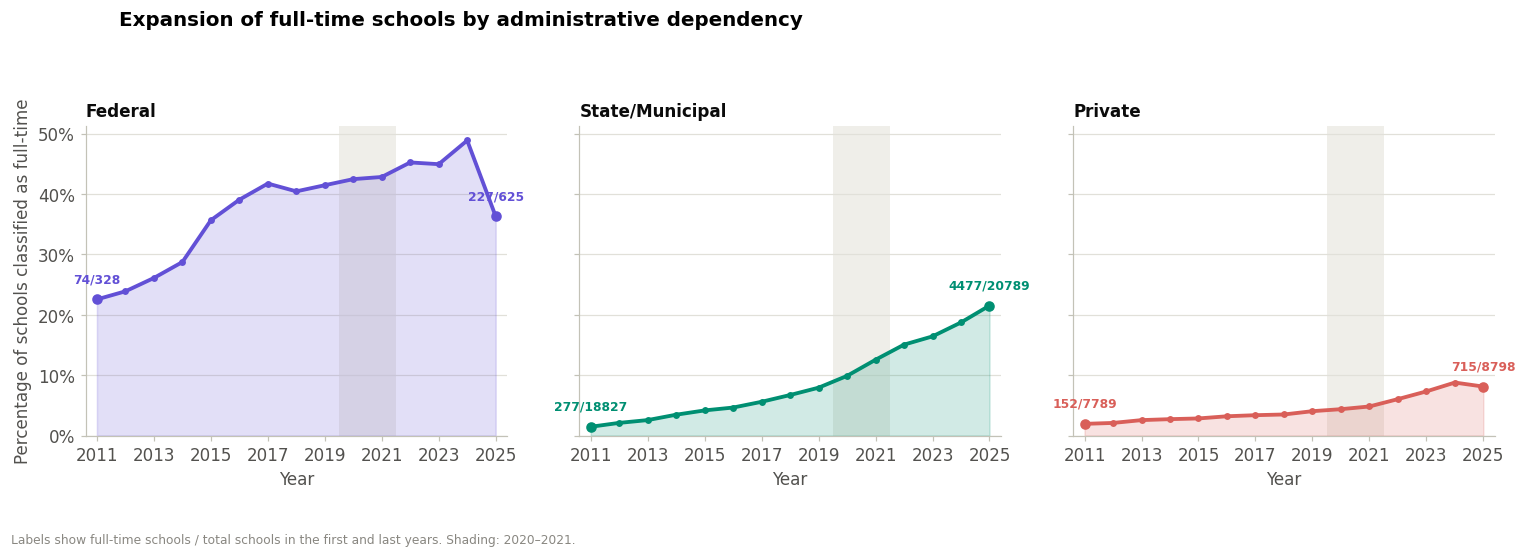

In [6]:

# ==========================================================
# GRÁFICO 1.1 — EXPANSÃO DAS ESCOLAS INTEGRAIS
# Evolução nacional por dependência administrativa
# ==========================================================

fig, axes = plt.subplots(
    1,
    len(DEPS_GRAFICO1_1),
    figsize=(14, 4.8),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.ravel()

for ax, dep in zip(axes, DEPS_GRAFICO1_1):

    dados = (
        tab1_1[tab1_1["DEP"] == dep]
        .sort_values("ANO")
    )

    anos = dados["ANO"].to_numpy()
    valores = dados["pct_integrais"].to_numpy()

    cor = COR_DEPENDENCIA[dep]

    # Destaque do período pandêmico
    sombra_pandemia(ax)

    # Área preenchida
    ax.fill_between(
        anos,
        valores,
        0,
        color=cor,
        alpha=0.18,
        zorder=1
    )

    # Linha principal
    ax.plot(
        anos,
        valores,
        color=cor,
        linewidth=2.5,
        marker="o",
        markersize=3.5,
        zorder=2
    )

    # Destaque dos anos inicial e final
    ax.scatter(
        [anos[0], anos[-1]],
        [valores[0], valores[-1]],
        color=cor,
        s=35,
        zorder=3
    )

    # Quantidades absolutas nos anos inicial e final
    for _, linha in dados.iloc[[0, -1]].iterrows():

        ax.annotate(
            f'{int(linha["integrais"])}/{int(linha["escolas"])}',
            xy=(linha["ANO"], linha["pct_integrais"]),
            xytext=(0, 11),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            fontweight="semibold",
            color=cor
        )

    # Título e eixos
    ax.set_title(
        T["dep"][dep],
        loc="left",
        fontsize=11,
        fontweight="semibold"
    )

    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(PCT)
    ax.set_xlabel(T["ano"])

    eixo_anos(ax, anos.tolist())

    ax.grid(axis="y", color=GRADE)
    ax.grid(axis="x", visible=False)

# Rótulo do eixo Y
axes[0].set_ylabel(
    "Percentage of schools classified as full-time"
    if IDIOMA == "en"
    else "Percentual de escolas classificadas como integrais"
)

# Título geral
fig.suptitle(
    "Expansion of full-time schools by administrative dependency"
    if IDIOMA == "en"
    else "Expansão das escolas integrais por dependência administrativa",
    x=0.08,
    ha="left",
    fontsize=13,
    fontweight="semibold"
)

# Nota metodológica
nota(
    fig,
    "Labels show full-time schools / total schools in the first and last years. Shading: 2020–2021."
    if IDIOMA == "en"
    else "Rótulos indicam escolas integrais / total de escolas nos anos inicial e final. Sombra: 2020–2021."
)

fig.tight_layout(rect=[0, 0.04, 1, 0.91])

salvar(fig, "g1_1_expansao_nacional_dependencia_area")

plt.show()


##### Pequena análise da queda da Federal em 2025

In [7]:

# ==========================================================
# TABELA 1 — DISTRIBUIÇÃO DAS MODALIDADES
# Rede Federal: 2024 e 2025
# ==========================================================

federal_anos = (
    df_g1[
        (df_g1["DEP"] == "Federal")
        & (df_g1["ANO"].isin([2024, 2025]))
    ].copy()
)

print("DISTRIBUIÇÃO DAS MODALIDADES — 2024")

display(
    federal_anos[federal_anos["ANO"] == 2024]
    ["ENS_PRED_EM"]
    .value_counts()
    .reindex(MODALIDADES, fill_value=0)
    .rename("Quantidade de escolas")
    .to_frame()
)

print("DISTRIBUIÇÃO DAS MODALIDADES — 2025")

display(
    federal_anos[federal_anos["ANO"] == 2025]
    ["ENS_PRED_EM"]
    .value_counts()
    .reindex(MODALIDADES, fill_value=0)
    .rename("Quantidade de escolas")
    .to_frame()
)


DISTRIBUIÇÃO DAS MODALIDADES — 2024


,Quantidade de escolas
ENS_PRED_EM,
Regular,266
Misto,53
Integral,305


DISTRIBUIÇÃO DAS MODALIDADES — 2025


,Quantidade de escolas
ENS_PRED_EM,
Regular,271
Misto,127
Integral,227


In [8]:

# ==========================================================
# TABELA 2 — MATRÍCULAS NAS ESCOLAS QUE MUDARAM
# Rede Federal: 2024 e 2025
# ==========================================================

COLS_MAT = [
    "CO_ESCOLA",
    "QT_MAT_EM_REG",
    "QT_MAT_EM_INT"
]

# Dados de matrícula em 2024
mat_2024 = (
    federal_anos[federal_anos["ANO"] == 2024]
    [["CO_ESCOLA"] + COLS_MAT[1:]]
    .rename(columns={
        "QT_MAT_EM_REG": "MAT_REG_2024",
        "QT_MAT_EM_INT": "MAT_INT_2024"
    })
)

# Dados de matrícula em 2025
mat_2025 = (
    federal_anos[federal_anos["ANO"] == 2025]
    [["CO_ESCOLA"] + COLS_MAT[1:]]
    .rename(columns={
        "QT_MAT_EM_REG": "MAT_REG_2025",
        "QT_MAT_EM_INT": "MAT_INT_2025"
    })
)

# Reunir classificações e matrículas
comparacao_matriculas = (
    comparacao_federal
    .merge(mat_2024, on="CO_ESCOLA")
    .merge(mat_2025, on="CO_ESCOLA")
)

# Selecionar escolas que mudaram de modalidade
mudancas_federal = comparacao_matriculas[
    comparacao_matriculas["MOD_2024"]
    != comparacao_matriculas["MOD_2025"]
].copy()

# Exibir matrículas dos dois anos
colunas_exibicao = [
    "CO_ESCOLA",
    "MOD_2024",
    "MOD_2025",
    "MAT_REG_2024",
    "MAT_INT_2024",
    "MAT_REG_2025",
    "MAT_INT_2025"
]

display(
    mudancas_federal[colunas_exibicao]
    .sort_values(["MOD_2024", "MOD_2025"])
)


NameError: name 'comparacao_federal' is not defined

#### Análise pelo total 

salvo: figuras_poster\g1_1b_quantidade_escolas_integrais.png / .svg


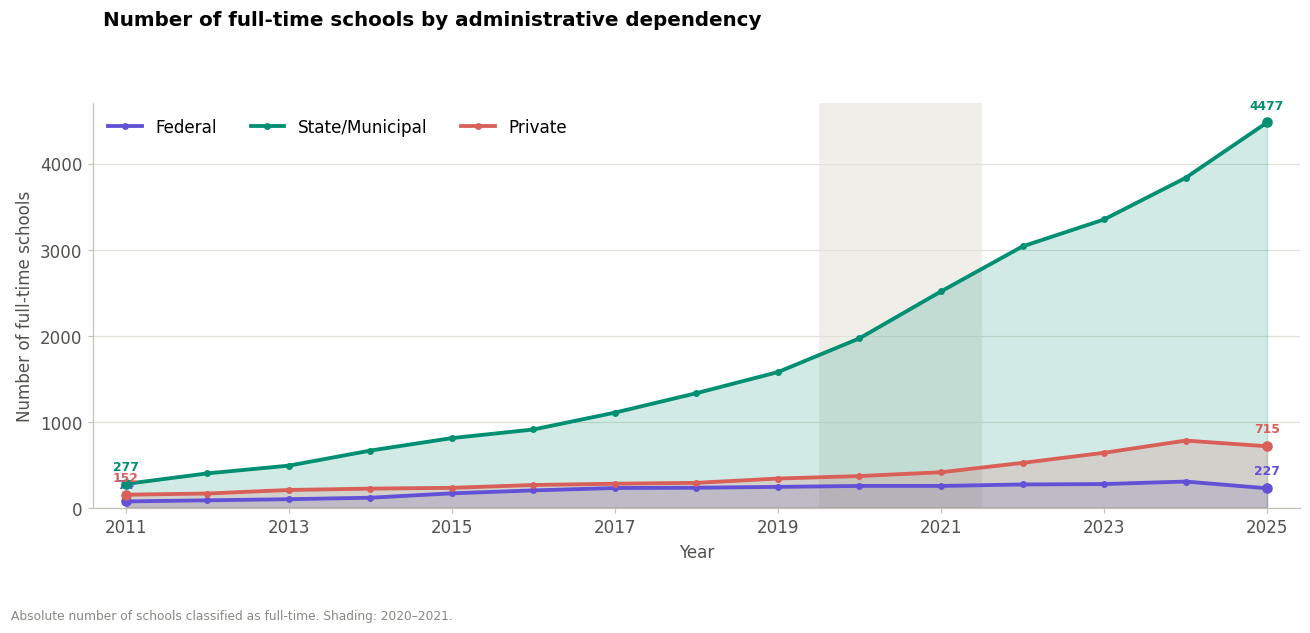

In [ ]:

# ==========================================================
# GRÁFICO 1.1B — QUANTIDADE DE ESCOLAS INTEGRAIS
# Evolução nacional por dependência administrativa
# ==========================================================

fig, ax = plt.subplots(figsize=(12, 5.5))

# Destaque do período pandêmico
sombra_pandemia(ax)

# ----------------------------------------------------------
# ÁREAS PREENCHIDAS POR DEPENDÊNCIA
# ----------------------------------------------------------

for dep in DEPS_GRAFICO1_1:

    dados = (
        tab1_1[tab1_1["DEP"] == dep]
        .sort_values("ANO")
    )

    anos = dados["ANO"].to_numpy()
    valores = dados["integrais"].to_numpy()

    cor = COR_DEPENDENCIA[dep]

    # Área preenchida
    ax.fill_between(
        anos,
        valores,
        0,
        color=cor,
        alpha=0.18,
        zorder=1
    )

    # Linha principal
    ax.plot(
        anos,
        valores,
        color=cor,
        linewidth=2.5,
        marker="o",
        markersize=3.5,
        label=T["dep"][dep],
        zorder=2
    )

    # Destaque dos anos inicial e final
    ax.scatter(
        [anos[0], anos[-1]],
        [valores[0], valores[-1]],
        color=cor,
        s=35,
        zorder=3
    )

    # Quantidades absolutas nos anos inicial e final
    for _, linha in dados.iloc[[0, -1]].iterrows():

        ax.annotate(
            f'{int(linha["integrais"])}',
            xy=(linha["ANO"], linha["integrais"]),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            fontweight="semibold",
            color=cor
        )

# ----------------------------------------------------------
# EIXOS E FORMATAÇÃO
# ----------------------------------------------------------

ax.set_ylim(bottom=0)

ax.set_ylabel(
    "Number of full-time schools"
    if IDIOMA == "en"
    else "Quantidade de escolas integrais"
)

ax.set_xlabel(T["ano"])

eixo_anos(ax, sorted(tab1_1["ANO"].unique().tolist()))

ax.grid(axis="y", color=GRADE)
ax.grid(axis="x", visible=False)

# Legenda
ax.legend(
    loc="upper left",
    frameon=False,
    ncol=len(DEPS_GRAFICO1_1)
)

# Título
fig.suptitle(
    "Number of full-time schools by administrative dependency"
    if IDIOMA == "en"
    else "Quantidade de escolas integrais por dependência administrativa",
    x=0.08,
    ha="left",
    fontsize=13,
    fontweight="semibold"
)

# Nota metodológica
nota(
    fig,
    "Absolute number of schools classified as full-time. Shading: 2020–2021."
    if IDIOMA == "en"
    else "Número absoluto de escolas classificadas como integrais. Sombra: 2020–2021."
)

fig.tight_layout(rect=[0, 0.04, 1, 0.92])

salvar(fig, "g1_1b_quantidade_escolas_integrais")

plt.show()


### Gráfico 1.2 - Evolução nacional das modalidades por dependência administrativa



Análise da evolução da modalidade regular no conjunto de escolas de cada dependência administrativa (Federal, Estadual/Municipal e Privada), ao longo do período analisado (2011-2025).

#### Tabela Regional

In [ ]:

# ==========================================================
# GRÁFICO 1.2 — PREPARAÇÃO DA ANÁLISE REGIONAL
# Escolas estaduais e municipais
# ==========================================================

# ----------------------------------------------------------
# 1. SELEÇÃO DOS DADOS
# ----------------------------------------------------------

g1_2 = (
    df_g1[
        df_g1["DEP"].isin(DEPS_GRAFICO1_2)
        & df_g1["ANO"].between(*ANOS_GRAFICO1)
    ]
    .copy()
)

# Identificar escolas integrais
g1_2["INTEGRAL"] = g1_2["ENS_PRED_EM"].eq("Integral")

# Conferência de duplicatas
duplicadas_g1_2 = int(
    g1_2.duplicated(["ANO", "CO_ESCOLA"]).sum()
)

print(
    f"Duplicatas escola-ano na análise regional: "
    f"{duplicadas_g1_2}"
)

# ----------------------------------------------------------
# 2. AGREGAÇÃO POR REGIÃO E ANO
# ----------------------------------------------------------

tab1_2 = (
    g1_2.groupby(["REGIAO", "ANO"])
    .agg(
        escolas=("CO_ESCOLA", "size"),
        integrais=("INTEGRAL", "sum")
    )
    .reset_index()
)

# Percentual de escolas integrais
tab1_2["pct_integrais"] = (
    100 * tab1_2["integrais"] / tab1_2["escolas"]
)

# ----------------------------------------------------------
# 3. MATRIZ DE PERCENTUAIS
# ----------------------------------------------------------

pct1_2 = (
    tab1_2.pivot(
        index="REGIAO",
        columns="ANO",
        values="pct_integrais"
    )
    .reindex(index=REGIOES)
    .reindex(columns=range(*ANOS_GRAFICO1[:1],) if False else sorted(tab1_2["ANO"].unique()))
    .astype(float)
)

ANOS_1_2 = pct1_2.columns.tolist()

# ----------------------------------------------------------
# 4. TOTAL NACIONAL DO RECORTE
# ----------------------------------------------------------

brasil_1_2 = (
    g1_2.groupby("ANO")
    .agg(
        escolas=("CO_ESCOLA", "size"),
        integrais=("INTEGRAL", "sum")
    )
)

brasil_1_2["pct_integrais"] = (
    100 * brasil_1_2["integrais"] / brasil_1_2["escolas"]
)

# ----------------------------------------------------------
# 5. SALVAR TABELAS
# ----------------------------------------------------------

tab1_2.to_csv(
    SAIDA / "tab1_2_integrais_regiao_ano.csv",
    index=False,
    encoding="utf-8-sig"
)

# Conferência dos percentuais regionais
display(pct1_2.round(2))

# Conferência dos totais nacionais do recorte
display(brasil_1_2.round(2))


Duplicatas escola-ano na análise regional: 0


ANO,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
REGIAO,,,,,,,,,,,,,,,
Norte,2.07,2.44,2.85,3.80,4.62,3.95,5.35,5.14,6.62,7.08,7.53,8.61,9.08,11.23,12.85
Nordeste,3.88,5.69,6.50,7.66,8.95,9.71,11.27,13.83,16.80,20.18,22.16,24.76,26.59,31.76,35.07
Centro-Oeste,1.36,1.49,2.28,2.97,3.80,4.36,6.60,8.55,9.46,11.56,14.01,18.98,20.69,20.73,20.38
Sudeste,0.69,1.06,1.61,2.72,3.69,4.90,5.65,6.45,6.93,9.05,13.57,16.99,18.64,20.07,21.73
Sul,1.39,1.67,1.65,2.09,2.54,2.27,2.55,2.48,2.85,3.16,3.53,3.62,4.04,5.79,9.51


,escolas,integrais,pct_integrais
ANO,,,
2011,19155,351,1.83
2012,19281,487,2.53
2013,19404,590,3.04
2014,19581,782,3.99
2015,19853,978,4.93
2016,20074,1112,5.54
2017,20279,1336,6.59
2018,20371,1565,7.68
2019,20444,1820,8.9


#### Mapa de calor regional

salvo: figuras_poster\g1_2_integrais_regiao_heatmap.png / .svg


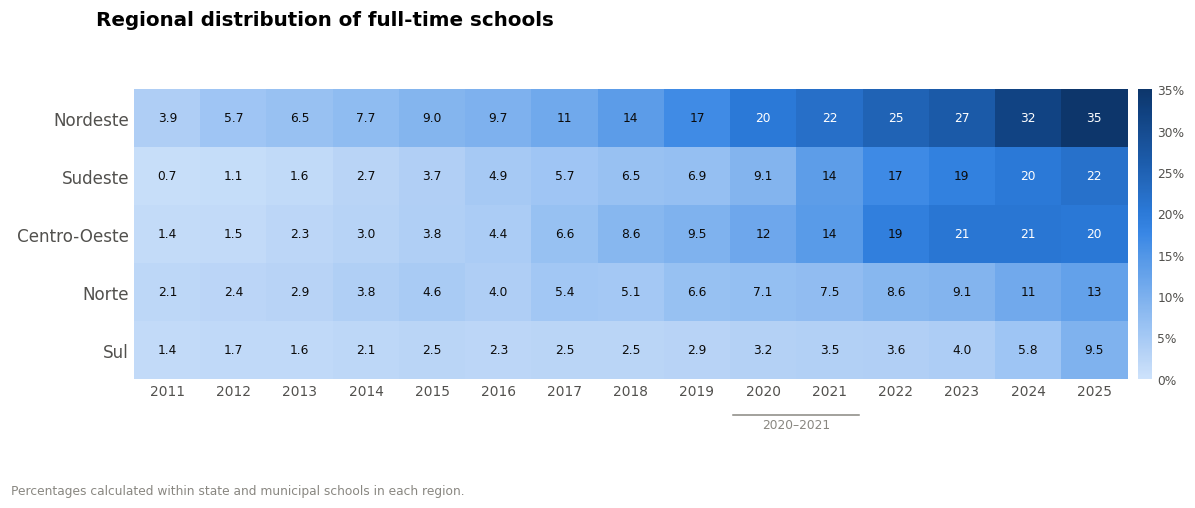

In [ ]:

# ==========================================================
# GRÁFICO 1.2 — MAPA DE CALOR REGIONAL
# Percentual de escolas integrais
# Dependências estadual e municipal
# ==========================================================

# ----------------------------------------------------------
# 1. ORGANIZAÇÃO DA MATRIZ
# ----------------------------------------------------------

# Ordenar regiões pelo percentual do último ano
ordem_regioes = (
    pct1_2[ANOS_1_2[-1]]
    .sort_values(ascending=False)
    .index.tolist()
)

# Matriz somente com as regiões
matriz = pct1_2.loc[ordem_regioes].astype(float)

linhas = ordem_regioes

# ----------------------------------------------------------
# 2. CONSTRUÇÃO DO MAPA DE CALOR
# ----------------------------------------------------------

cmap = LinearSegmentedColormap.from_list(
    "azul",
    RAMPA_AZUL
)

vmax = np.nanmax(matriz.to_numpy())

fig, ax = plt.subplots(
    figsize=(11, 0.55 * len(linhas) + 1.6)
)

im = ax.imshow(
    matriz.to_numpy(),
    aspect="auto",
    cmap=cmap,
    vmin=0,
    vmax=vmax
)

# Eixos
ax.set_xticks(
    range(len(ANOS_1_2)),
    ANOS_1_2,
    fontsize=9
)

ax.set_yticks(
    range(len(linhas)),
    linhas
)

ax.tick_params(length=0)
ax.grid(False)

# Remover bordas
for s in ax.spines.values():
    s.set_visible(False)


# ----------------------------------------------------------
# 3. VALORES NAS CÉLULAS
# ----------------------------------------------------------

for i in range(len(linhas)):
    for j in range(len(ANOS_1_2)):

        v = matriz.iat[i, j]

        if pd.notna(v):

            ax.text(
                j,
                i,
                f"{v:.0f}" if v >= 10 else f"{v:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if v > 0.55 * vmax else TINTA
            )

# ----------------------------------------------------------
# 4. DESTAQUE DO PERÍODO PANDÊMICO
# ----------------------------------------------------------

if all(ano in ANOS_1_2 for ano in ANOS_PANDEMIA):

    j0 = ANOS_1_2.index(ANOS_PANDEMIA[0])
    j1 = ANOS_1_2.index(ANOS_PANDEMIA[1])

    y_traco = len(linhas) - 0.5 + 0.62

    ax.plot(
        [j0 - 0.45, j1 + 0.45],
        [y_traco, y_traco],
        color=APAGADO,
        lw=1,
        clip_on=False
    )

    ax.text(
        (j0 + j1) / 2,
        y_traco + 0.06,
        T["pandemia"],
        ha="center",
        va="top",
        fontsize=8,
        color=APAGADO
    )

ax.set_ylim(len(linhas) - 0.5, -0.5)

# ----------------------------------------------------------
# 5. LEGENDA E TÍTULO
# ----------------------------------------------------------

cb = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.01
)

cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8, length=0)
cb.ax.yaxis.set_major_formatter(PCT)

fig.suptitle(
    "Regional distribution of full-time schools"
    if IDIOMA == "en"
    else "Distribuição regional das escolas integrais",
    x=0.08,
    ha="left",
    fontsize=13,
    fontweight="semibold"
)

nota(
    fig,
    (
        "Percentages calculated within state and municipal schools in each region."
        if IDIOMA == "en"
        else "Percentuais calculados sobre o total de escolas estaduais e municipais em cada região."
    ),
)

fig.tight_layout(rect=[0, 0.04, 1, 0.94])

salvar(fig, "g1_2_integrais_regiao_heatmap")

plt.show()


# 6. Gráfico 2

# 7. Gráfico 3